<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_14_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

딥러닝 파이토치 교과서 ch13. p.708~732

## 03. 적대적 생성 신경망(GAN)이란

적대적 학습에서는 판별자를 먼저 학습시킨 후 생성자를 학습시키는 과정을 반복. 판별자 학습은 크게 두 단계로 진행

먼저 실제 이미지를 입력해서 네트워크(신경망)가 해당 이미지를 진짜로 분류하도록 학습시킴

그런 다음 생성자가 생성한 모조 이미지를 입력해서 해당 이미지를 가짜로 분류하도록 학습시킴

이 과정을 거쳐 판별자는 실제 이미지를 진짜로 분류하고, 모조 이미지를 가짜로 분류

<img src="https://drive.google.com/uc?export=view&id=1OlmsK-IbgJmReMYms5uZtzR5OBuLF13Y" width="400">

생성자는 분류에 성공할 확률을 낮추고 판별자는 분류에 성공할 확률을 높이면서 서로 경쟁적으로 발전시키는 구조

### 1) GAN 동작 원리

적대적 생성 신경망(GAN)은 생성자와 판별자 네트워크 두 개로 구성되어 있음

생성자 G는 판별자 D를 속이려고 원래 이미지와 최대한 비슷한 이미지를 만들도록 학습함

반대로 판별자 D는 원래 이미지와 생성자 G가 만든 이미지를 잘 구분하다록 학습을 진행함

<img src="https://drive.google.com/uc?export=view&id=1WCiKsKHtXQJ_3C12p22vCll8W7AmQyzj" width="400">

이미지 x가 입력으로 주어졌을 때 판별자 D의 출력에 해당하는 D(x)가 진짜 이미지일 확률을 반환

반면 생성자 G의 역할은 판별자 D가 진짜인지 가짜인지 구별할 수 없을 만큼 진짜와 같은 모조 이미지를 노이즈 데이터를 사용하여 만들어 내는 것

예를 들어 실제 이미지인 알파벳 z가 입력으로 주어졌을 때 판별자는 z를 학습. 또한, 생성자는 임의의 노이즈 데이터를 사용하여 모조 이미지 z'(G(z))를 생성. 이러한 G(z)를 다시 판별자 D의 입력으로 주면 판별자는 G(z)가 실제 이미지일 확률을 반환

<img src="https://drive.google.com/uc?export=view&id=1QwHb3i3dSOm8CWj_0kXG7NNRMVs3VDIM" width="300">

GAN의 손실 함수는 다음과 같음

<img src="https://drive.google.com/uc?export=view&id=1hJp0sDTAUJ5odr_nPa79iRgnFYYQmhWy" width="400">

수식에서 판별자 D는 실제 이미지 x를 입력받을 경우 D(x)를 1로 예측하고, 생성자가 잠재 벡터에서 생성한 모조 이미지 G(z)를 입력받을 경우 D(G(z))를 0으로 예측.

따라서 판별자가 모조 이미지 G(z)를 입력받을 경우 1로 예측하도록 하는 것이 목표



### 2) GAN 구현




In [1]:
import imageio
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pylab as plt

from torchvision.utils import make_grid, save_image
import torchvision.datasets as datasets
import torchvision.transforms as transforms
plt.style.use('ggplot')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
batch_size = 512
epochs = 200
sample_size = 64
nz = 128
k =1

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,),(0.5,)),
])

train_dataset = datasets.MNIST(
    root="/content/080289/chap13/data", train=True, transform=transform, download=True)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.00MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.5MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [4]:
class Generator(nn.Module):
  def __init__(self, nz):
    super(Generator, self).__init__()
    self.nz = nz
    self.main = nn.Sequential(
        nn.Linear(self.nz, 256),
        nn.LeakyReLU(0.2),
        nn.Linear(256, 512),
        nn.LeakyReLU(0.2),
        nn.Linear(512,1024),
        nn.LeakyReLU(0.2),
        nn.Linear(1024,784),
        nn.Tanh()
    )
  def forward(self, x):
    return self.main(x).view(-1,1,28,28)

In [5]:
class Discriminator(nn.Module):
  def __init__(self):
    super(Discriminator, self).__init__()
    self.n_input = 784
    self.main = nn.Sequential(
        nn.Linear(self.n_input, 1024),
        nn.LeakyReLU(0.2),
        nn.Dropout(0.3),
        nn.Linear(1024, 512),
        nn.LeakyReLU(0.2),
        nn.Dropout(0.3),
        nn.Linear(512, 256),
        nn.LeakyReLU(0.2),
        nn.Dropout(0.3),
        nn.Linear(256, 1),
        nn.Sigmoid(),
    )
  def forward(self, x):
    x = x.view(-1, 784)
    return self.main(x)

In [6]:
generator = Generator(nz).to(device)
discriminator = Discriminator().to(device)
print(generator)
print(discriminator)

Generator(
  (main): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (main): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, out_features=1, bias=True)
    (10): Sigmoid()
  )
)


In [7]:
optim_g = optim.Adam(generator.parameters(), lr=0.0002)
optim_d = optim.Adam(discriminator.parameters(), lr=0.0002)

criterion = nn.BCELoss()

losses_g = []
losses_d = []
images = []

In [8]:
def save_generator_image(image, path):
  save_image(image, path)

In [9]:
def train_discriminator(optimizer, data_real, data_fake):
  b_size = data_real.size(0)
  real_label = torch.ones(b_size, 1).to(device)
  fake_label = torch.zeros(b_size, 1).to(device)
  optimizer.zero_grad()
  output_real = discriminator(data_real)
  loss_real = criterion(output_real, real_label)
  output_fake = discriminator(data_fake)
  loss_fake = criterion(output_fake, fake_label)
  loss_real.backward()
  loss_fake.backward()
  optimizer.step()
  return loss_real + loss_fake

In [10]:
def train_generator(optimizer, data_fake):
  b_size = data_fake.size(0)
  real_label = torch.ones(b_size, 1).to(device)
  optimizer.zero_grad()
  output = discriminator(data_fake)
  loss = criterion(output, real_label)
  loss.backward()
  optimizer.step()
  return loss

In [11]:
batch_size = 64
epochs = 30

generator.train()
discriminator.train()

for epoch in range(epochs):
  loss_g = 0.0
  loss_d = 0.0
  for idx, data in tqdm(enumerate(train_loader),
                        total=int(len(train_dataset)/train_loader.batch_size)):
    image, _ = data
    image = image.to(device)
    b_size = len(image)
    for step in range(k):
      data_fake = generator(torch.randn(b_size, nz).to(device)).detach()
      data_real = image
      loss_d += train_discriminator(optim_d, data_real, data_fake)
    data_fake = generator(torch.randn(b_size, nz).to(device))
    loss_g += train_generator(optim_g, data_fake)
  generated_img = generator(torch.randn(b_size, nz).to(device)).cpu().detach()
  generated_img = make_grid(generated_img)
  save_generator_image(generated_img, f"/content/080289/chap13/gen_img{epoch}.png")
  epoch_loss_g = loss_g / idx
  epoch_loss_d = loss_d / len(train_loader)
  losses_g.append(epoch_loss_g)
  losses_d.append(epoch_loss_d)

  print(f"Epoch {epoch} of {epochs}")
  print(f"Generator loss: {epoch_loss_g:.8f}, Discriminator loss: {epoch_loss_d:.8f}")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
118it [00:12,  9.28it/s]                         


Epoch 0 of 30
Generator loss: 1.50435293, Discriminator loss: 0.85785371


118it [00:12,  9.29it/s]                         

Epoch 1 of 30
Generator loss: 2.50964308, Discriminator loss: 1.43311858



118it [00:12,  9.52it/s]                         

Epoch 2 of 30
Generator loss: 4.30217457, Discriminator loss: 0.47446746


... (50 outputs left out)


118it [00:13,  9.05it/s]                         

Epoch 28 of 30
Generator loss: 2.64809775, Discriminator loss: 0.62547767



118it [00:12,  9.11it/s]                         

Epoch 29 of 30
Generator loss: 2.20689034, Discriminator loss: 0.63977420


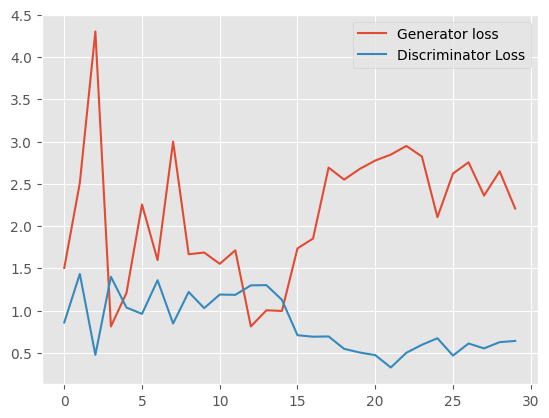

In [12]:
plt.figure()
losses_g = [f1.item() for f1 in losses_g]
plt.plot(losses_g, label='Generator loss')
losses_d = [f2.item() for f2 in losses_d]
plt.plot(losses_d, label='Discriminator Loss')
plt.legend()

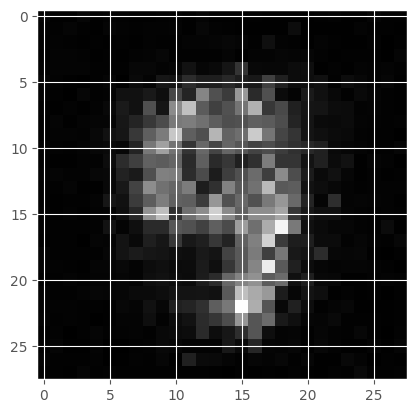

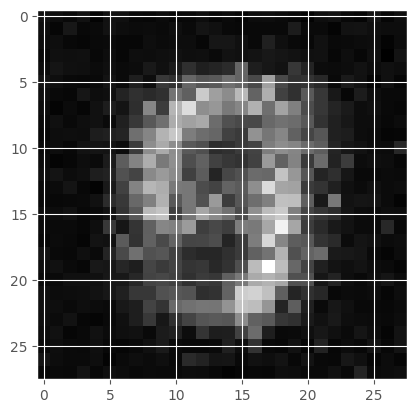

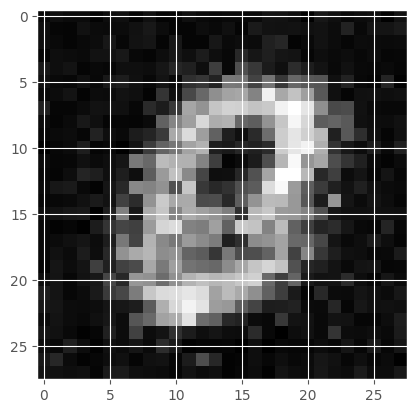

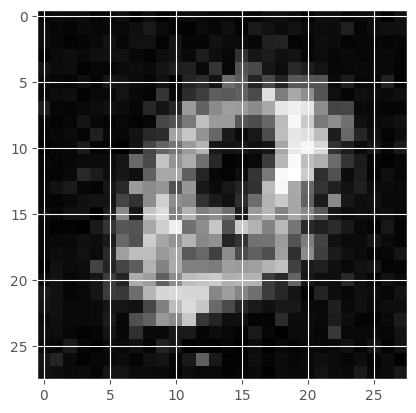

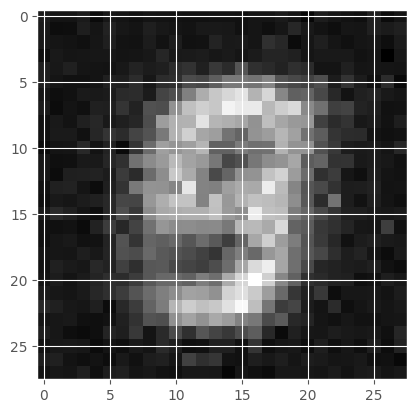

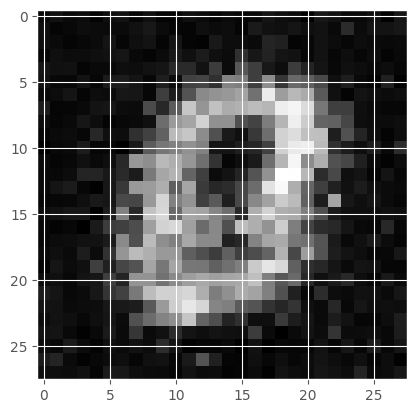

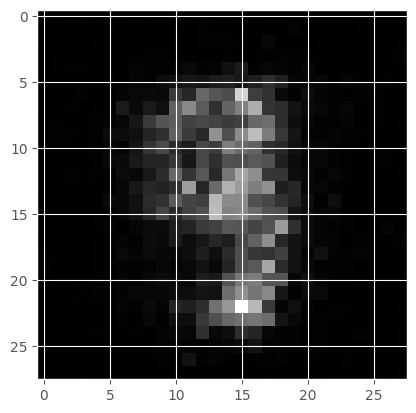

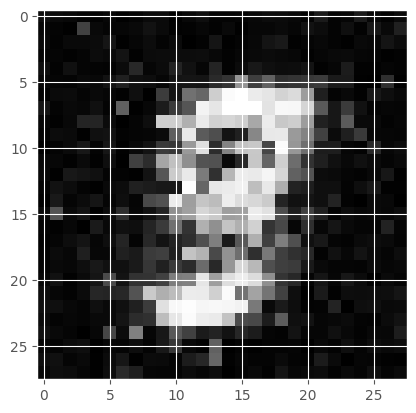

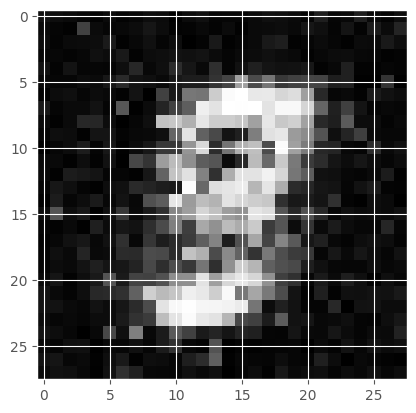

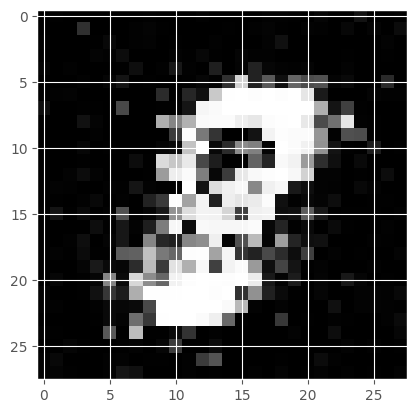

In [13]:
import numpy as np

fake_images = generator(torch.randn(b_size, nz).to(device))
for i in range(10):
  fake_images_img = np.reshape(fake_images.data.cpu().numpy()[i],(28, 28))
  plt.imshow(fake_images_img, cmap='gray')
  plt.savefig('/content/080289/chap13/fake_images_img' + str(i) +'.png')
  plt.show()

## 04. GAN 파생 기술

GAN: 생성자와 판별자가 서로 대결하면서 학습하는 구조이기 때문에 학습이 매우 불안정

생성자와 판별자 중 한쪽으로 치우친 훈련이 발생하면 성능에 문제가 생겨 정상적이 분류가 불가능

이러한 제약을 해결한 모델이 DCGAN.

이름에서도 알 수 있듯이 DCGAN은 GAN 학습에 CNN을 사용하는 것

GAN과 DCGAN이 가짜 이미지 생성을 위해 임의의 노이즈 값을 사용했다면 cGAN은 출력에 어떤 조건을 주어 변형하는 모델

즉, GAN이 임의의 노이즈로 무작위 이미지를 출력한다면, cGAN은 시드 역할을 하는 임의의 노이즈와 함께 어떤 조건이 추가됨

CycleGAN은 사진이 주어졌을 때 다른 사진으로 변형시키는 모델


### 1) DCGAN

DCGAN: GAN과 동일하게 입력된 이미지를 바탕으로 그것과 매우 유사한 가짜 이미지를 만들고, 이를 평가하는 과정을 반복하여 실제와 매우 유사한 이미지를 생산하는 학습법

**생성자 네트워크**

<img src="https://drive.google.com/uc?export=view&id=15yCZ_Uuatm1NuGcCCrlFSjsNKXtiiptl" width="400">

생성자 네트원크 특징은 다음과 같음
- 풀링층을 모두 엇애고, 분소-스트라이드 합성곱을 사용
- 배치 정규화를 이용하여 네트워크의 층이 많아도 안정적으로 기울기를 계산할 수 있도록 했음
- 활성화 함수는 렐루를 사용하며, 최종 출력층에서는 하이퍼볼릭 탄젠트를 사용

**판별자 네트워크**

판별자 네트워크는 64 X 64 크기의 이미지를 입력받아 진짜 혹은 가짜의 1차원 결과를 출력

<img src="https://drive.google.com/uc?export=view&id=1247qP9nZphtEvq4j0BM3Y1w12tZ5zIn2" width="400">

판별자 네트워크 특징은 다음과 같음
- 풀링층을 모두 없애고, 스트라이드 합성곱을 사용
- 배치 정규화를 이용하여 네트워크의 층이 많아도 안정적으로 기울기를 계산할 수 있도록 했음
- 활성화 함수는 리키렐루를 사용하며, 최종 출력층에서는 시그모이드를 사용


### 2) cGAN

cGAN은 GAN의 출력에 조건을 주어 통제하려는 시도에서 만들어짐

기본적으로 GAN 원리와 비슷하지만, 다음 그림과 같이 생성자와 판별자에 조건을 입력하는 부분에서 차이가 있음

<img src="https://drive.google.com/uc?export=view&id=1GdANZHGQ1W-hFiQmhElKkl4wHhaC0Tfm" width="300">


### 3) CycleGAN

GAN과 DCGAN은 랜덤 노이즈를 입력으로 하므로 무작위 데이터가 생성되기 때문에 원하는 결
과를 얻기 어려운 문제가 있음

이러한 문제를 해결하는 방법으로 PIX2PIX가 있음

**PIX2PIX**

PIX2PIX: 임의의 노이즈 벡터가 아닌 이미지를 입력으로 받아 다른 스타일의 이미지를 출력하는 지도 학습 알고리즘

<img src="https://drive.google.com/uc?export=view&id=1B3oRGC08wMNnwimfsJxVjfIQT5XPBRaL" width="250">

**생성자 네트워크**

PIX2PIX의 생성자 네트워크는 일반적인 생성자의 구조와 조금 다름

입력과 출력이 모두 이미지이기 때문에 전체적으로 크기가 줄어들었다가 다시 커지는 인코더 - 디코더의 구조

크기가 줄어드는 인코더에서는 입력 데이터의 특징을 찾아내고, 크기가 다시 커지는 디코더에서는 이미지를 생성하는 역할을 함

<img src="https://drive.google.com/uc?export=view&id=1PL2_VRosSnaTFh3beTeJbkrSj4inhN4d" width="350">

**판별자 네트워크**

판별자 네트워크는 DCCGAN과 마찬가지로 스트라이드가 2인 합성곱층으로 구성되어 있음

판별자는 이미지를 통째로 진짜인지 아닌지 판별하는 것이 아니라 이미지의 각 부분이 진짜인지 아닌지 판별. 이 과정에 따라 좀 더 디테일한 부분에 집중한 이미지를 판별할 수 있음

L1 손실 함수가 추가된 최종 손실 함수는 다음과 같이 수정하여 사용됨

<img src="https://drive.google.com/uc?export=view&id=1lYC6urS-Q356ivdxZUSm8eEU8G1caClw" width="250">

**CycleGAN**

PIX2PIX가 강력한 모델이기는 하지만 데이터 쌍이 필요하다는 단점이 있음


CycleGAN은 하나가 아닌 두 개(G, F)의 생성자를 갖음

생성자 G는 이미지 X를 이미지 Y로 변환하며, 생성자 F는 이미지 Y를 다시 이미지 X로 변환. 이때 Dx와 Dy는 각각 이미지 X와 Y를 위한 판별자.

따라서 생성자 G는 Dy에 대한 적대적 학습을 하며, 생성자 F는 Dx에 대한 적대적 학습을 함

<img src="https://drive.google.com/uc?export=view&id=13jDs2_k24l6JMb2r-rok8MPEFjN-QzQX" width="400">

CycleGAN에서는 G(X)=Y'에 대한 생성자, Y' 값을 다시 X'로 복원하는 F(Y')=X'에 대한 생성자와 이 값을 판별하는 판별자(Dy, Dx)가 추가되어 총 네 개의 네트워크를 사용

X -> Y', Y' -> X'로 연결되는 것을 순화 일관성

다음 그림은 X -> Y', Y' -> X'로 연결되는 동작 과정을 보여 줌

X -> Y'를 정방향 일관성이라고 하며, Y' -> X'를 역방향 일관성이라고 함
